In [40]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [42]:
df = pd.read_csv("Social_Network_Ads.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())
print(df.isnull().sum())

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
Dataset shape: (400, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [44]:
df = df.drop_duplicates()
df = df.dropna(subset=[
    "Age", "EstimatedSalary", "Purchased"
])

X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

print("Features:", X.columns.tolist())
print("Target classes:", y.unique())

Features: ['Age', 'EstimatedSalary']
Target classes: [0 1]


In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 300
Testing records: 100


In [48]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Predictions:", y_pred)
print("Actual values:", y_test.to_numpy())

Predictions: [0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 0 0
 0 1 0 0 1 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 1 0 0 0
 0 1 1 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 1 0 1 0 0 1]
Actual values: [1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 1 1 0 0 1 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 0 0
 0 0 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 1 1 0 1 0 0 0
 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 1]


In [50]:
cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)

print("Confusion Matrix:\n", cm)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("Accuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Confusion Matrix:
 [[60  4]
 [ 5 31]]
True Negatives: 60
False Positives: 4
False Negatives: 5
True Positives: 31
Accuracy: 0.91
Error Rate: 0.09
Precision: 0.8857
Recall: 0.8611


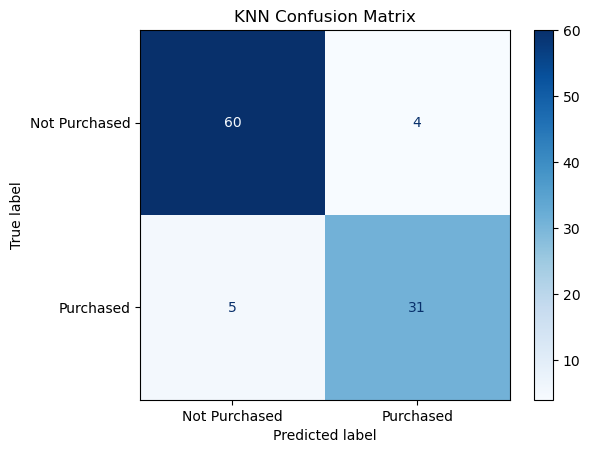

In [52]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Purchased", "Purchased"]
)

disp.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

In [55]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Purchased", "Purchased"],
    zero_division=0
))

               precision    recall  f1-score   support

Not Purchased       0.92      0.94      0.93        64
    Purchased       0.89      0.86      0.87        36

     accuracy                           0.91       100
    macro avg       0.90      0.90      0.90       100
 weighted avg       0.91      0.91      0.91       100



In [57]:
age = 35
salary = 60000

new_customer = pd.DataFrame({
    "Age": [age],
    "EstimatedSalary": [salary]
})

new_customer_scaled = scaler.transform(new_customer)

prediction = knn.predict(new_customer_scaled)[0]

if prediction == 1:
    print("Customer is likely to purchase.")
else:
    print("Customer is unlikely to purchase.")

Customer is unlikely to purchase.
